# QFT and QPE: explicit circuits

Run with the pinned environment or the public code package. Standalone downloads can place `qft_qpe.py` beside this notebook. Qiskit 2.6.2 is Apache-2.0; this generator and notebook are MIT. The known phase is a pedagogical correctness task.

In [1]:
from pathlib import Path
import sys, os, math
root = Path.cwd()
if not (root / "src").is_dir() and (root.parent / "src").is_dir():
    root = root.parent
if (root / "src").is_dir():
    sys.path.insert(0, str(root / "src"))
try:
    from openquantum.qft_qpe import *
except ModuleNotFoundError:
    from qft_qpe import *  # Download qft_qpe.py beside this notebook.
from qiskit.quantum_info import Operator
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg")


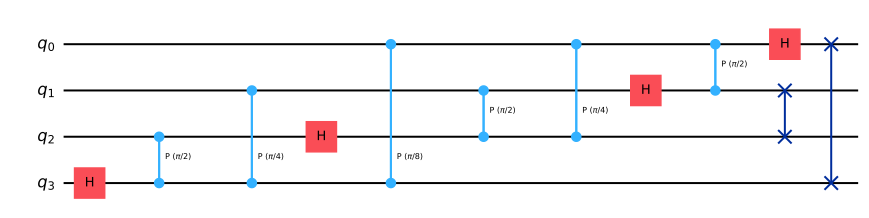

In [2]:
fourier = build_qft(4)
np.testing.assert_allclose(Operator(fourier).data, qft_matrix(4), atol=1e-13, rtol=0)
display(fourier.draw(output="mpl", fold=32))
plt.close("all")

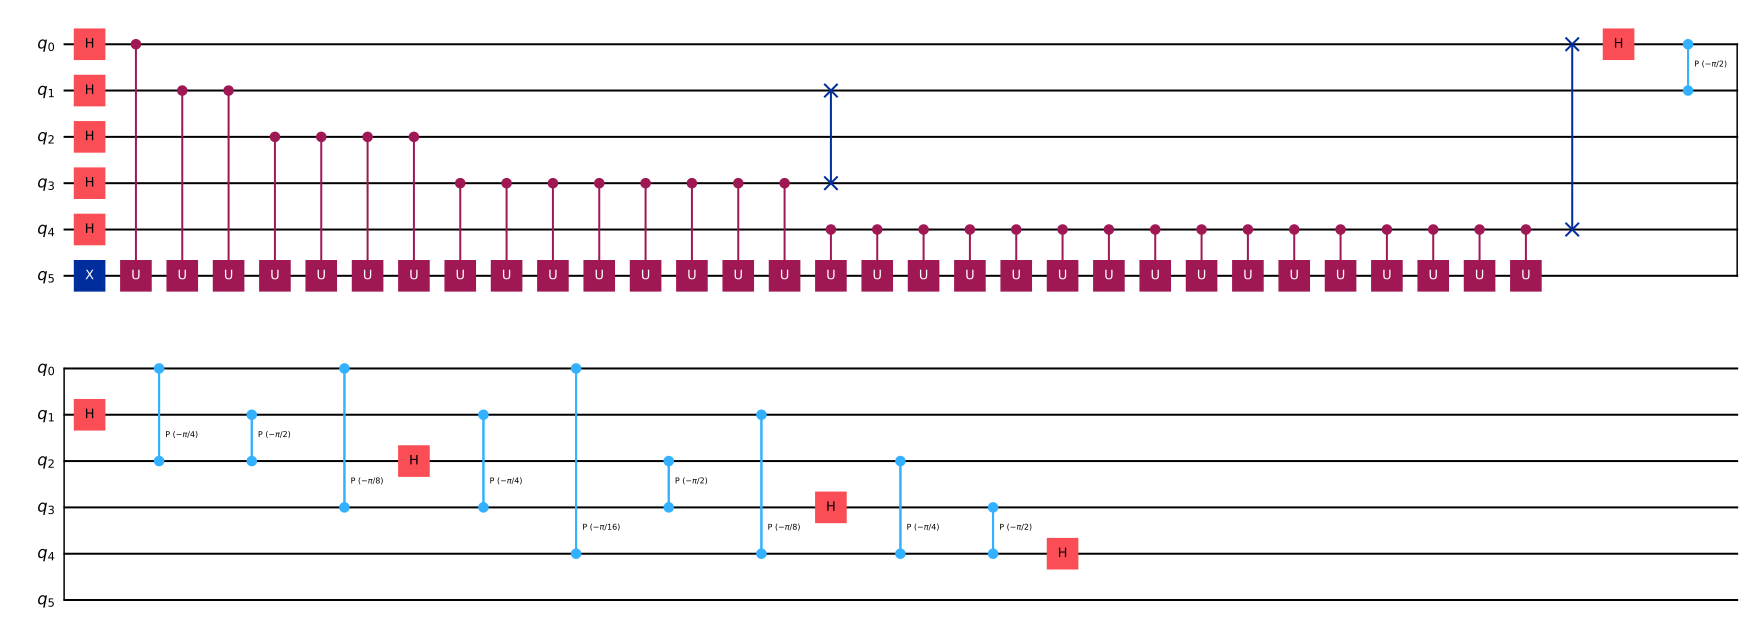

In [3]:
phase, m = 0.3, 5
unitary, preparation = phase_gate_example(phase)
circuit = build_qpe(m, unitary, preparation)
display(circuit.draw(output="mpl", fold=36))
plt.close("all")

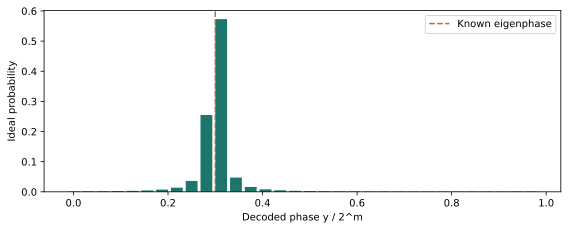

In [4]:
probabilities = simulate_qpe(circuit, m)
reference = qpe_distribution(phase, m)
np.testing.assert_allclose(probabilities, reference, atol=3e-13, rtol=0)
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(np.arange(2**m)/2**m, probabilities, width=0.8/2**m, color="#1c766c")
ax.axvline(phase, color="#c4633d", linestyle="--", label="Known eigenphase")
ax.set(xlabel="Decoded phase y / 2^m", ylabel="Ideal probability")
ax.legend(); fig.tight_layout(); plt.show(); plt.close(fig)

In [5]:
repetitions = median_repetitions(0.005)
rng = np.random.default_rng(731)
outputs = rng.choice(2**m, size=repetitions, p=probabilities)
median = float(np.median(outputs)/2**m)
assert abs(median-phase) <= 1/2**m
print({"ideal_draws": outputs.tolist(), "repetitions": repetitions, "median_phase": median,
       "target_phase_error": 1/2**m,
       "scope": "seeded ideal circuit draws; not hardware executions"})

{'ideal_draws': [10, 30, 13, 10, 10, 8, 9, 9, 10, 8, 10, 10, 10, 9, 10], 'repetitions': 15, 'median_phase': 0.3125, 'target_phase_error': 0.03125, 'scope': 'seeded ideal circuit draws; not hardware executions'}


{'qubits': 5, 'cutoff': 2, 'measured_spectral_error': 0.9427934736519933, 'telescoping_bound': 0.9817477042468103, 'controlled_phases': 7}


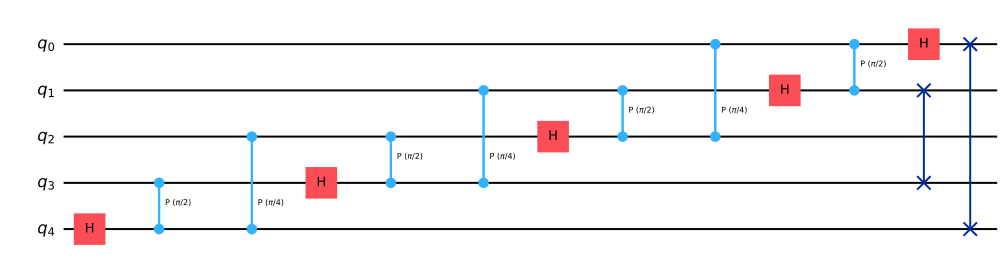

In [6]:
approx = build_qft(5, max_distance=2)
error = float(np.linalg.norm(Operator(approx).data - qft_matrix(5), ord=2))
bound = qft_omission_bound(5, 2)
assert error <= bound + 1e-12
print({"qubits": 5, "cutoff": 2, "measured_spectral_error": error,
       "telescoping_bound": bound, "controlled_phases": int(approx.count_ops()["cp"])})
display(approx.draw(output="mpl", fold=32)); plt.close("all")

In [7]:
ledger = qpe_ledger(m, unitary, preparation)
print(ledger)
# All controlled powers are repeated actual supplied U calls.
assert ledger["controlled_unitary_calls_per_execution"] == 2**m - 1

{'phase_bits': 5, 'target_qubits': 1, 'logical_qubits': 6, 'classical_output_bits': 5, 'input_preparations_per_execution': 1, 'controlled_unitary_calls_per_execution': 31, 'controlled_powers': [1, 2, 4, 8, 16], 'supplied_unitary_source_operations': 1, 'supplied_preparation_source_operations': 1, 'source_operation_upper_guard': 72, 'source_count_semantics': 'recognized CP/MCX/CCX gates count as single source operations; this guard does not bound nested transpilation work', 'decomposed_gate_counts': {'h': 10, 'rz': 123, 'x': 1, 'cx': 88, 'measure': 5}, 'decomposed_dependency_depth': 160, 'depth_semantics': 'circuit dependencies; no physical feed-forward latency or scheduling model', 'variant': 'textbook QPE', 'rotation_synthesis_performed': False, 'scope': 'all supplied preparation, controlled access, Fourier/feedback gates, reset and final phase readout', 'excluded': ['construction of application unitary and eigenstate beyond supplied circuits', 'classical compilation/phase decoding run

## Live bounded exploration

A local or Binder kernel can regenerate the circuit and distribution. The static book reuses the checked saved outputs and omits kernel widgets.

In [8]:
def inspect_phase(phase=0.3, phase_bits=5):
    u, prep = phase_gate_example(float(phase))
    demo = build_qpe(int(phase_bits), u, prep)
    actual = simulate_qpe(demo, int(phase_bits))
    np.testing.assert_allclose(actual, qpe_distribution(float(phase), int(phase_bits)), atol=3e-13, rtol=0)
    return {"phase": phase, "most_likely_grid_phase": int(np.argmax(actual))/2**int(phase_bits),
            "controlled_U_calls": 2**int(phase_bits)-1, "logical_qubits": demo.num_qubits}
for test_phase in (0.0, 0.125, 0.3, 0.5, 0.999):
    inspect_phase(test_phase, 5)
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    display(widgets.interactive(inspect_phase,
        phase=widgets.FloatSlider(value=.3,min=0,max=.99,step=.01),
        phase_bits=widgets.IntSlider(value=5,min=1,max=6)))

## Larger exports without simulation

Controlled access is still explicitly materialized; the source and primitive caps apply. This cell counts a generated circuit and makes no large-state validation claim.

In [9]:
u, prep = phase_product_example(8, 0.3)
larger = build_qpe(8, u, prep, measure=True)
lowered = lower_circuit(larger)
print({"logical_qubits": larger.num_qubits, "controlled_U_calls": 255,
       "decomposed_operations": sum(lowered.count_ops().values()), "simulation_performed": False})

{'logical_qubits': 16, 'controlled_U_calls': 255, 'decomposed_operations': 10384, 'simulation_performed': False}
